<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/13_Encrypted_Malicious_Traffic_Detection/HybridQML_EncryptedTraffic_Sodar2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical SVM / KNN for network-traffic classification: Sodar et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Gokul Sunil Sodar, Akshay Murthy, Annapurna Jonnalagadda and Aswani Kumar Cherukuri, "Encrypted network traffic analysis
> using quantum machine learning", *EPJ Quantum Technology* 13, 17 (2026). DOI 10.1140/epjqt/s40507-025-00459-7

The paper publishes no code. Everything below is written from its description (Sections 3 and 4, Algorithms 1-3, Appendices A-C),
with the software stack the paper names: **PennyLane** with the `lightning.qubit` simulator for every quantum circuit, and
scikit-learn for SVM, KNN and the metrics.

**What the notebook does.** It downloads the two public datasets of the paper from a Hugging Face mirror (ISCX-URL2016, the
benign-vs-defacement URL task, and ISCXIDS2012, normal-vs-attack flows), applies the paper's cleaning (drop duplicates and
missing values, label-encode categorical columns, undersample the majority class), and trains five variants of each of two
classifiers, exactly as the paper's Tables 2 and 3:

| Variant | What it is |
|---|---|
| Regular | scikit-learn SVM / KNN on standardised features |
| Quantum (Angle / Amplitude) | **QSVM** (SVM on a quantum fidelity kernel) and **QKNN** (k-nearest neighbours with distance $1-\text{fidelity}$), the data encoded by angle (one RY gate per feature) or amplitude encoding |
| Hybrid (Angle / Amplitude) | quantum encoding circuit, Pauli-Z expectation values read out, a *classical* SVM / KNN trained on those numbers |

It adds a random-forest reference, repeated runs over several random seeds (mean $\pm$ std; the paper reports one split), the paper's
Appendix-C hyper-parameter rows, an ablation without IP addresses, a cost estimate of running every kernel entry as a real
circuit on a simulator, and a final side-by-side table with a verdict per number of the paper.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane; if Colab asks to restart the session, do so and run all cells again. With `FAST_MODE = True` (default) the
whole notebook runs in about 10 minutes (smaller samples, two seeds); with `FAST_MODE = False` it uses the full datasets and
five seeds (the run time of the saved outputs is printed in the last code cell).

**What you get at the end.** Tables in the layout of the paper's Tables 2 and 3, bar charts and confusion matrices, and an honest
verdict for every number: "reproduced", "not reached" or "exceeded", plus a critical reading that also shows what the
"quantum" kernels of this paper actually compute.

## The paper in one page

**Problem.** Classify network records as benign or malicious when the payload is encrypted and only metadata is visible. The paper
studies whether quantum encodings of such metadata help classical and quantum classifiers.

**Decision.** Binary: benign (0) vs malicious (1). Metrics: accuracy, precision, recall, F1 (positive class = malicious).

**Methods (Section 3, Algorithms 1-3).**

1. **QSVM.** `sklearn.svm.SVC` with a *custom kernel*: $K(x_i,x_j)=|\langle\phi(x_i)|\phi(x_j)\rangle|^2$ (Eq. 1), obtained by applying the
   encoding of $x_i$, then the adjoint of the encoding of $x_j$, and measuring the probability of the all-zero state (Alg. 1). Only the lower
   triangle of the Gram matrix is computed and mirrored; kernel entries are evaluated in parallel with joblib.
2. **QKNN.** From scratch: fidelity $F=|\langle\psi(x_1)|\psi(x_2)\rangle|^2$, distance $d=1-F$ (Eq. 2), the $k$ smallest distances, majority vote (Alg. 2).
   Data scaled with `MaxAbsScaler` and clipped to $[0,1]$. The fidelity circuit applies the encoding, "two layers of entanglement using CNOT gates and fixed RY gate".
3. **Hybrid QML.** The encoding circuit is run on every sample, the Pauli-Z expectation values $\langle Z_i\rangle$ are read out as new features
   (Alg. 3), and a plain scikit-learn SVM or KNN (k = 7, Euclidean, distance weighting) is trained on them.
4. **Encodings.** *Angle*: one qubit per feature, RY rotation. *Amplitude*: the whole (normalised, zero-padded) feature vector becomes the amplitude vector of $\lceil\log_2 d\rceil$ qubits.

**Data (Section 4.1).**
- **ISCX-URL2016** (benign vs *defacement* URLs): 15 features; duplicates and missing values dropped; benign undersampled to the size of the defacement class.
- **ISCXIDS2012** (normal vs attack flows): 20 raw features, most unstructured columns discarded; duplicates and missing values dropped; categorical columns label-encoded; normal undersampled to the size of the attack class.
- Classical baselines use `StandardScaler`.

**Claims to check (Tables 2 and 3, Section 5.2).** Hybrid models with amplitude encoding are on par with or slightly better than the classical models
(URL: hybrid SVM 0.9667 vs regular 0.9634; hybrid KNN 0.9878 vs 0.9874); pure quantum models lag behind on URL and approach the classical ones on IDS; hybrid models beat pure
quantum ones; KNN beats SVM on both datasets; pure quantum simulation is one to two orders of magnitude slower than classical and hybrid models.
All numbers come from **one** train-test split per configuration.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Datasets | ISCX-URL2016 (15 features) and ISCXIDS2012 (20 raw features) from UNB/CIC | Same two datasets from the public Hugging Face mirror `bencorn/` (the UNB site needs a form). URL: the 15-feature file `Defacement_Infogain.csv` (it has exactly 15 numeric features + class and the duplicate count implied by the paper's balancing). IDS: the labelled flow CSVs of three of the six days (Sat 12, Sun 13, Mon 14 June 2010; the tar file keeps them first, so only a few MB are streamed). Not the same flows as the authors' unspecified subset |
| URL task | benign vs one malicious class; "defacement" implied by "undersampled the benign class to match the defacement class" | benign (0) vs Defacement (1) |
| IDS features | "20 features"; unstructured and high-missing columns discarded, rest not listed | 13 columns: appName, 4 byte/packet counters, direction, both TCP-flag columns, source, destination, protocolName, sourcePort, destinationPort. Payload and timestamp columns dropped. Missing TCP flags (UDP/ICMP flows) filled with the category "None" instead of dropping those rows # CHOICE |
| Categorical encoding | label encoding | `LabelEncoder` per column, IP addresses included, as in the paper (ablation in Section 7 removes them) |
| Class balance | undersample the majority class | random undersampling to the minority size, optionally capped (`URL_PER_CLASS`, `IDS_PER_CLASS`) for speed # CHOICE |
| Split | train/test, ratio not given | stratified 80/20, `random_state` = seed # CHOICE (the paper's quantum test sets of 300 and 240 samples in Appendix C imply 1,500 / 1,200 samples at 20 %) |
| Scaling (classical, hybrid input) | `StandardScaler` for the classical models; "scaler normalization" for the rest | classical models: `StandardScaler`; all quantum encodings: `MaxAbsScaler` then clip to $[0,1]$ (the paper states this for QKNN and for amplitude encoding) # CHOICE: used for QSVM and hybrid too |
| Angle encoding | RY(x) per feature, one qubit per feature | `qml.AngleEmbedding(..., rotation="Y")`, angle = scaled feature in $[0,1]$ rad |
| Amplitude encoding | amplitude embedding on $\log_2 d$ qubits | `qml.AmplitudeEmbedding(pad_with=0, normalize=True)` on 4 qubits (15 features padded to 16) |
| Hybrid read-out | $\langle Z_i\rangle$ of the n qubits | angle: 15 / 13 values; amplitude: 4 values (the paper's Alg. 3 says n = number of features; extra qubits would carry constant $\langle Z\rangle=+1$) # CHOICE |
| Hybrid classifiers | SVC, KNN k = 7 Euclidean distance-weighted | SVC (RBF, `gamma="scale"`, C = 1), `KNeighborsClassifier(7, weights="distance")` |
| QSVM | custom kernel, lower triangle + joblib | exact state-vector kernel in NumPy (identical numbers, verified against the PennyLane circuit), lower-triangle trick kept; `SVC(kernel="precomputed", C=1)` |
| QKNN | k not given for Tables 2-3; Appendix C: 5 and 15 | k = 7 for Tables 2-3 # CHOICE, k = 5 and 15 in Section 6 |
| QKNN circuit | encoding + 2 layers of CNOT + fixed RY | implemented with RY(pi/4) # CHOICE; proven to leave the fidelity unchanged (Section 3) |
| Quantum sample sizes | 300 / 240 test samples (Appendix C); Table 2/3 sizes not stated | all balanced data in the main run, plus the paper-size subsets (1,500 / 1,200 samples) in Section 6 |
| Seeds | one split | `SEEDS` (2 in FAST mode, 5 otherwise), mean $\pm$ std |
| Hardware | none (simulators) | none; `IBM_TOKEN` is unused |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("pennylane_lightning") is None:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0" huggingface_hub
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and pennylane-lightning already present; skipping pip install.")

pennylane and pennylane-lightning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: smaller samples and 2 seeds, whole notebook in about 10 minutes. False: full data, 5 seeds.
SEED      = 42             # base seed; every split, sample and classifier uses a seed from SEEDS
SEEDS     = [42, 43] if FAST_MODE else [42, 43, 44, 45, 46]
E3_SEEDS  = SEEDS[:3]      # hyper-parameter rows (Section 6b) use at most three seeds

TEST_SIZE     = 0.20       # CHOICE: stratified 80/20 split (paper: ratio not given)
URL_PER_CLASS = 2500 if FAST_MODE else None   # CHOICE: cap per class after de-duplication (None = all, 4,506 per class)
IDS_PER_CLASS = 2500 if FAST_MODE else 5500   # CHOICE: cap per class (paper's hybrid test set of ~2,200 flows implies ~5,500 per class)
N_Q_URL, N_Q_IDS = 1500, 1200                 # paper-size subsets for the pure quantum models (Appendix C: test sets of 300 and 240)
KNN_K    = 7               # paper: k = 7, Euclidean, distance weighting for the hybrid and classical KNN
QKNN_K   = 7               # CHOICE: Tables 2-3 do not give k for QKNN; Appendix C tries 5 and 15 (run in Section 6)
RF_TREES = 200             # random-forest reference (not in the paper)

DATA_DIR  = "iscx_data"    # downloaded files are cached here
URL_REPO, URL_FILE = "bencorn/ISCX-URL-2016", "Defacement_Infogain.csv"
IDS_REPO_FILE = "datasets/bencorn/ISCX-IDS-2012/iscxids2012-master.tar.gz"
IDS_DAYS = ["TestbedSatJun12Flows.csv", "TestbedSunJun13Flows.csv", "TestbedMonJun14Flows.csv"]   # CHOICE: days with attacks that are small to fetch
URL_PATH = ""              # optional: path of your own copy of Defacement_Infogain.csv (skips the download)
IDS_DIR  = ""              # optional: folder holding the three Testbed*Flows.csv files (skips the download)
IBM_TOKEN = ""             # unused: the paper ran simulators only

In [3]:
import os, time, tarfile, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MaxAbsScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pennylane as qml

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
NOTEBOOK_T0 = time.time()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds =", SEEDS)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1
FAST_MODE = False | seeds = [42, 43, 44, 45, 46]


## 1. Data: two CIC datasets from a public mirror

Both datasets come from the Canadian Institute for Cybersecurity. The UNB download pages ask for a form, so the notebook uses the
copies in the Hugging Face repositories `bencorn/ISCX-URL-2016` and `bencorn/ISCX-IDS-2012` (licence tag "cc").

- **ISCX-URL2016** is a table of 79 lexical features per URL (length, digit counts, entropies, ...) with five classes. The mirror also holds
  "information-gain" reduced files; `Defacement_Infogain.csv` has exactly **15** features and the classes benign / Defacement, which is the
  paper's "15 features" and its benign-vs-defacement balancing sentence.
- **ISCXIDS2012** is seven days of testbed traffic summarised as flow records (QRadar) with a *Normal* / *Attack* tag. The mirror holds the
  authors' 1 GB repository archive. The three days used here are stored first in the archive, so the notebook streams only the first
  few megabytes and stops. Attack content: Sat 12 June (brute force, few), Sun 13 June (infiltration from inside), Mon 14 June (HTTP DoS).
  If the stream fails, the code falls back to downloading the whole archive (1 GB).

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)
URL_FEATURES = ["domain_token_count", "avgpathtokenlen", "tld", "domainlength", "ArgUrlRatio", "argDomanRatio", "argPathRatio",
                "NumberofDotsinURL", "CharacterContinuityRate", "NumberRate_URL", "NumberRate_FileName", "NumberRate_AfterPath",
                "SymbolCount_Domain", "Entropy_Domain", "Entropy_Extension"]

def load_url_raw():
    if URL_PATH:
        return pd.read_csv(URL_PATH)
    path = os.path.join(DATA_DIR, URL_FILE)
    if not os.path.exists(path):
        from huggingface_hub import hf_hub_download
        try:
            hf_hub_download(URL_REPO, URL_FILE, repo_type="dataset", local_dir=DATA_DIR)
        except Exception as e:                                       # fallback: rebuild the 15 columns from the full Defacement file
            print("Infogain file not reachable (", type(e).__name__, "); rebuilding the 15 columns from Defacement.csv")
            p = hf_hub_download(URL_REPO, "Defacement.csv", repo_type="dataset", local_dir=DATA_DIR)
            full = pd.read_csv(p)
            full[URL_FEATURES + ["URL_Type_obf_Type"]].rename(columns={"URL_Type_obf_Type": "class"}).to_csv(path, index=False)
    return pd.read_csv(path)

def fetch_ids_csvs(dest):
    os.makedirs(dest, exist_ok=True)
    want = set(IDS_DAYS)
    have = {f for f in os.listdir(dest) if f in want}
    if have == want:
        return
    def extract(tar):
        for m in tar:
            b = os.path.basename(m.name)
            if m.isfile() and "/data/CSV/" in m.name and b in want and b not in have:
                with open(os.path.join(dest, b), "wb") as g:
                    src = tar.extractfile(m)
                    while True:
                        chunk = src.read(1 << 22)
                        if not chunk:
                            break
                        g.write(chunk)
                have.add(b)
                print("  extracted", b)
                if have == want:
                    break
    try:                                                              # stream the first few MB of the 1 GB archive
        from huggingface_hub import HfFileSystem
        with HfFileSystem().open(IDS_REPO_FILE, "rb") as f, tarfile.open(fileobj=f, mode="r|gz") as tar:
            extract(tar)
    except Exception as e:
        print("Streaming failed (", type(e).__name__, e, "); downloading the full archive (1 GB) instead")
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("bencorn/ISCX-IDS-2012", "iscxids2012-master.tar.gz", repo_type="dataset", local_dir=dest)
        have.clear()
        with tarfile.open(p, "r:gz") as tar:
            extract(tar)
    assert have == want, f"missing IDS files: {want - have}"

IDS_COLS = ["appName", "totalSourceBytes", "totalDestinationBytes", "totalDestinationPackets", "totalSourcePackets", "direction",
            "sourceTCPFlagsDescription", "destinationTCPFlagsDescription", "source", "protocolName", "sourcePort",
            "destination", "destinationPort"]

def load_ids_raw():
    folder = IDS_DIR or os.path.join(DATA_DIR, "ids2012")
    if not IDS_DIR:
        fetch_ids_csvs(folder)
    frames = [pd.read_csv(os.path.join(folder, d), usecols=IDS_COLS + ["Label"], low_memory=False) for d in IDS_DAYS]
    return pd.concat(frames, ignore_index=True)

url_raw = load_url_raw()
ids_raw = load_ids_raw()
print("ISCX-URL2016 (Defacement_Infogain):", url_raw.shape, url_raw["class"].value_counts().to_dict())
print("ISCXIDS2012 (3 days, 13 columns kept):", ids_raw.shape, ids_raw["Label"].value_counts().to_dict())
display(url_raw.head(3)); display(ids_raw.head(3))

ISCX-URL2016 (Defacement_Infogain): (15711, 16) {'Defacement': 7930, 'benign': 7781}


ISCXIDS2012 (3 days, 13 columns kept): (580101, 14) {'Normal': 553881, 'Attack': 26220}


,domain_token_count,avgpathtokenlen,tld,domainlength,ArgUrlRatio,argDomanRatio,argPathRatio,NumberofDotsinURL,CharacterContinuityRate,NumberRate_URL,NumberRate_FileName,NumberRate_AfterPath,SymbolCount_Domain,Entropy_Domain,Entropy_Extension,class
0,4.0,4.4,4.0,25.0,0.034,0.08,0.077,5.0,0.6,0.017,0.067,-1.0,3.0,0.784,0.0,Defacement
1,4.0,6.0,4.0,25.0,0.030,0.08,0.059,4.0,0.6,0.000,0.000,-1.0,3.0,0.784,0.0,Defacement
2,4.0,5.8,4.0,25.0,0.031,0.08,0.061,4.0,0.6,0.000,0.000,-1.0,3.0,0.784,0.0,Defacement


,appName,totalSourceBytes,totalDestinationBytes,totalDestinationPackets,totalSourcePackets,direction,sourceTCPFlagsDescription,destinationTCPFlagsDescription,source,protocolName,sourcePort,destination,destinationPort,Label
0,HTTPWeb,128,64,1,2,L2R,"F,A","F,A",192.168.1.104,tcp_ip,22441,216.246.64.49,80,Normal
1,HTTPWeb,128,64,1,2,L2R,"F,A","F,A",192.168.1.104,tcp_ip,22445,216.246.64.66,80,Normal
2,HTTPWeb,128,64,1,2,L2R,"F,A","F,A",192.168.1.104,tcp_ip,22444,216.246.64.66,80,Normal


## 2. Cleaning, labels and class balance (Section 4.1)

Following the paper: drop duplicate records and rows with missing values, label-encode the categorical columns, then undersample the
majority class to the size of the minority class. The label is 1 for the malicious class (Defacement / Attack) and 0 otherwise.

Two choices are ours and marked `# CHOICE`: the TCP-flag columns are missing for every UDP/ICMP flow, so the missing value is filled with the
category "None" (dropping those rows would silently remove all non-TCP traffic); and the sampling can be capped per class so that the quantum
kernels stay affordable. The order of operations (de-duplicate, balance, then split) is the paper's. Because the data are de-duplicated *before*
the split, no identical row appears on both sides, but near-duplicates still can (see the critical-reading section).

In [5]:
def prepare_url(raw):
    df = raw.drop_duplicates().dropna()
    y = (df["class"] == "Defacement").astype(int).values            # 1 = malicious
    X = df.drop(columns="class").astype(float).reset_index(drop=True)
    return X, y

def prepare_ids(raw, drop_cols=()):
    cols = [c for c in IDS_COLS if c not in drop_cols]
    df = raw[cols + ["Label"]].copy()
    for c in ["sourceTCPFlagsDescription", "destinationTCPFlagsDescription"]:
        if c in df:
            df[c] = df[c].fillna("None")                             # CHOICE: keep UDP/ICMP flows
    df = df.drop_duplicates().dropna()
    y = (df["Label"] == "Attack").astype(int).values                 # 1 = malicious
    X = df.drop(columns="Label").reset_index(drop=True)
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = LabelEncoder().fit_transform(X[c].astype(str))   # label encoding as in the paper
    return X.astype(float), y

def balanced_sample(X, y, per_class, seed):
    r = np.random.default_rng(seed)
    n = int(min(np.bincount(y)))
    if per_class is not None:
        n = min(n, int(per_class))
    idx = np.concatenate([r.choice(np.where(y == k)[0], n, replace=False) for k in (0, 1)])
    r.shuffle(idx)
    return X.values[idx], y[idx]

URL_X, URL_y = prepare_url(url_raw)
IDS_X, IDS_y = prepare_ids(ids_raw)
for name, raw_n, X, y in [("ISCX-URL2016", len(url_raw), URL_X, URL_y), ("ISCXIDS2012", len(ids_raw), IDS_X, IDS_y)]:
    print(f"{name:13s} raw rows {raw_n:>8,d} -> after de-duplication/NaN removal {len(X):>8,d} | benign {int((y==0).sum()):,d}, malicious {int((y==1).sum()):,d} | {X.shape[1]} features")
print("URL features:", list(URL_X.columns))
print("IDS features:", list(IDS_X.columns))

ISCX-URL2016  raw rows   15,711 -> after de-duplication/NaN removal   10,869 | benign 6,363, malicious 4,506 | 15 features
ISCXIDS2012   raw rows  580,101 -> after de-duplication/NaN removal  414,149 | benign 398,339, malicious 15,810 | 13 features
URL features: ['domain_token_count', 'avgpathtokenlen', 'tld', 'domainlength', 'ArgUrlRatio', 'argDomanRatio', 'argPathRatio', 'NumberofDotsinURL', 'CharacterContinuityRate', 'NumberRate_URL', 'NumberRate_FileName', 'NumberRate_AfterPath', 'SymbolCount_Domain', 'Entropy_Domain', 'Entropy_Extension']
IDS features: ['appName', 'totalSourceBytes', 'totalDestinationBytes', 'totalDestinationPackets', 'totalSourcePackets', 'direction', 'sourceTCPFlagsDescription', 'destinationTCPFlagsDescription', 'source', 'protocolName', 'sourcePort', 'destination', 'destinationPort']


## 3. The quantum part: encodings, the QSVM kernel circuit and the QKNN fidelity circuit

All circuits below are PennyLane circuits on `lightning.qubit`, as in the paper.

- **Angle encoding.** One qubit per feature, $R_Y(x_i)|0\rangle=\cos(x_i/2)|0\rangle+\sin(x_i/2)|1\rangle$. The state of $d$ qubits is a *product state*.
- **Amplitude encoding.** The vector $x/\|x\|$, zero-padded to $2^q$ entries, becomes the amplitude vector of $q=\lceil\log_2 d\rceil$ qubits (15 features -> 4 qubits).
- **QSVM kernel circuit (Alg. 1).** Encode $x_a$, apply the *adjoint* of the encoding of $x_b$, read the probability of the all-zero outcome; this equals $|\langle\phi(x_b)|\phi(x_a)\rangle|^2$.
- **Hybrid features (Alg. 3).** Encode $x$ and return $\langle Z_i\rangle$ for every qubit. For angle encoding $\langle Z_i\rangle=\cos x_i$ exactly; for amplitude encoding it is a signed sum of squared amplitudes.

Evaluating one circuit per kernel entry is what makes the paper's QSVM slow. A state-vector simulator gives the *same numbers* much
faster if we compute the states once and take inner products, so the full Gram matrices below use NumPy state vectors. Before relying
on that, the cell checks it against the actual PennyLane kernel circuits on random pairs.

In [6]:
_DEVS = {}
def dev(n):
    if n not in _DEVS:
        _DEVS[n] = qml.device("lightning.qubit", wires=n)
    return _DEVS[n]

def n_amp_qubits(d):
    return int(np.ceil(np.log2(d)))

# ---------- hybrid feature circuits (Alg. 3): encoding -> <Z_i> for every qubit
_NODES = {}
def hybrid_node(kind, d):
    key = (kind, d)
    if key not in _NODES:
        n = d if kind == "angle" else n_amp_qubits(d)
        @qml.qnode(dev(n))
        def node(x):
            if kind == "angle":
                qml.AngleEmbedding(x, wires=range(n), rotation="Y")
            else:
                qml.AmplitudeEmbedding(x, wires=range(n), pad_with=0.0, normalize=True)
            return [qml.expval(qml.PauliZ(i)) for i in range(n)]
        _NODES[key] = node
    return _NODES[key]

def quantum_features(Q, kind, chunk=1000):
    # the circuit is run with parameter broadcasting on blocks of rows; 1e-9 keeps all-zero rows normalisable
    node = hybrid_node(kind, Q.shape[1])
    Qe = Q + 1e-9 if kind == "amp" else Q
    return np.vstack([np.stack([np.atleast_1d(o) for o in node(Qe[i:i + chunk])], axis=1) for i in range(0, len(Q), chunk)])

# ---------- kernel circuits (Alg. 1): P(all zeros) after encode(a) then adjoint(encode(b))
_KNODES = {}
def kernel_node(kind, d):
    key = (kind, d)
    if key not in _KNODES:
        n = d if kind == "angle" else n_amp_qubits(d)
        @qml.qnode(dev(n))
        def node(a, b):
            if kind == "angle":
                qml.AngleEmbedding(a, wires=range(n), rotation="Y")
                qml.adjoint(qml.AngleEmbedding)(b, wires=range(n), rotation="Y")
            else:
                qml.AmplitudeEmbedding(a, wires=range(n), pad_with=0.0, normalize=True)
                qml.adjoint(qml.AmplitudeEmbedding)(b, wires=range(n), pad_with=0.0, normalize=True)
            return qml.probs(wires=range(n))
        _KNODES[key] = node
    return _KNODES[key]

def kernel_circuit(a, b, kind):
    if kind == "amp":
        a, b = a + 1e-9, b + 1e-9                                  # same epsilon as amp_state()
    return float(kernel_node(kind, len(a))(a, b)[0])

# ---------- fast exact kernels (same numbers, one state per sample instead of one circuit per pair)
def amp_state(Q):
    P = np.zeros((len(Q), 2 ** n_amp_qubits(Q.shape[1])))
    P[:, :Q.shape[1]] = Q + 1e-9
    return P / np.linalg.norm(P, axis=1, keepdims=True)

def _angle_block(A, B):
    K = np.ones((len(A), len(B)))
    for f in range(A.shape[1]):                                    # product state: |<a|b>|^2 = prod_f cos^2((a_f - b_f)/2)
        K *= 0.5 * (1.0 + np.cos(A[:, f, None] - B[None, :, f]))
    return K

def gram(A, B, kind, block=1000):
    # B is None: Gram matrix of A with itself -> lower triangle of blocks computed, upper triangle mirrored (paper's trick)
    if kind == "amp":
        SA = amp_state(A); SB = SA if B is None else amp_state(B)
        return (SA @ SB.T) ** 2
    if B is not None:
        return np.vstack([_angle_block(A[i:i + block], B) for i in range(0, len(A), block)])
    K = np.empty((len(A), len(A)))
    for i in range(0, len(A), block):
        for j in range(0, i + 1, block):
            blk = _angle_block(A[i:i + block], A[j:j + block])
            K[i:i + block, j:j + block] = blk
            K[j:j + block, i:i + block] = blk.T
    return K

# ---------- check: circuits vs fast formulas on random pairs of real (scaled) training rows
Xs, ys_ = balanced_sample(URL_X, URL_y, 300, SEED)
Qs = np.clip(MaxAbsScaler().fit_transform(Xs), 0, 1)
pairs = rng.integers(0, len(Qs), size=(10, 2))
for kind in ("angle", "amp"):
    k_circ = np.array([kernel_circuit(Qs[i], Qs[j], kind) for i, j in pairs])
    K_fast = gram(Qs, None, kind)
    k_fast = np.array([K_fast[i, j] for i, j in pairs])
    print(f"{kind:5s} kernel: PennyLane circuit vs NumPy states on 10 pairs -> allclose = {np.allclose(k_circ, k_fast, atol=1e-8)} (max |diff| = {np.abs(k_circ - k_fast).max():.1e})")
    assert np.allclose(k_circ, k_fast, atol=1e-8)
Zang = quantum_features(Qs[:50], "angle")
print("hybrid angle features = cos(x):", np.allclose(Zang, np.cos(Qs[:50])))
Zamp = quantum_features(Qs[:50], "amp")
S = amp_state(Qs[:50]) ** 2
idx = np.arange(S.shape[1])
Zref = np.stack([S @ (1 - 2 * ((idx >> (int(np.log2(S.shape[1])) - 1 - q)) & 1)) for q in range(Zamp.shape[1])], axis=1)
print("hybrid amplitude features = signed sums of squared amplitudes:", np.allclose(Zamp, Zref))
assert np.allclose(Zang, np.cos(Qs[:50])) and np.allclose(Zamp, Zref)

# ---------- what the circuits look like (4 qubits, one toy sample)
x4 = np.array([0.5, 1.0, 0.25, 0.8])
print("\nAngle-encoding hybrid circuit (Fig. 9 of the paper):")
print(qml.draw(hybrid_node("angle", 4), decimals=2)(x4))
print("\nAmplitude-encoding hybrid circuit (Fig. 8):")
print(qml.draw(hybrid_node("amp", 4), decimals=2)(x4))
print("\nQSVM kernel circuit, angle encoding (Fig. 7):")
print(qml.draw(kernel_node("angle", 4), decimals=2)(x4, x4[::-1].copy()))

angle kernel: PennyLane circuit vs NumPy states on 10 pairs -> allclose = True (max |diff| = 6.7e-16)


amp   kernel: PennyLane circuit vs NumPy states on 10 pairs -> allclose = True (max |diff| = 4.4e-16)


hybrid angle features = cos(x): True


hybrid amplitude features = signed sums of squared amplitudes: True

Angle-encoding hybrid circuit (Fig. 9 of the paper):
0: ─╭AngleEmbedding(M0)─┤  <Z>
1: ─├AngleEmbedding(M0)─┤  <Z>
2: ─├AngleEmbedding(M0)─┤  <Z>
3: ─╰AngleEmbedding(M0)─┤  <Z>

M0 = 
[0.5  1.   0.25 0.8 ]

Amplitude-encoding hybrid circuit (Fig. 8):
0: ─╭|Ψ⟩─┤  <Z>
1: ─╰|Ψ⟩─┤  <Z>

QSVM kernel circuit, angle encoding (Fig. 7):
0: ─╭AngleEmbedding(M0)─╭AngleEmbedding(M1)†─┤ ╭Probs
1: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
2: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)†─┤ ├Probs
3: ─╰AngleEmbedding(M0)─╰AngleEmbedding(M1)†─┤ ╰Probs

M0 = 
[0.5  1.   0.25 0.8 ]
M1 = 
[0.8  0.25 1.   0.5 ]


### The QKNN fidelity circuit with "two layers of CNOT and fixed RY"

The QKNN of the paper applies, after the encoding, two layers of CNOT gates and fixed RY rotations to *every* sample before computing the overlap. The same
unitary $W$ is applied to both states, and $|\langle W\phi(a)|W\phi(b)\rangle|^2=|\langle\phi(a)|W^\dagger W|\phi(b)\rangle|^2=|\langle\phi(a)|\phi(b)\rangle|^2$. The extra layers therefore
cannot change a single fidelity or a single neighbour list. The cell below builds exactly that circuit in PennyLane and confirms it numerically, so the fast fidelity of Section 4 is a faithful
implementation of the paper's QKNN. (The rotation angle is not given in the paper; $\pi/4$ is our choice, and any other value gives the same result.)

In [7]:
def entangling_layers(n, theta=np.pi / 4, layers=2):          # CHOICE: theta; paper: "two layers of CNOT and fixed RY"
    for _ in range(layers):
        for i in range(n - 1):
            qml.CNOT(wires=[i, i + 1])
        for i in range(n):
            qml.RY(theta, wires=i)

_SNODES = {}
def state_node(kind, d, with_W):
    key = (kind, d, with_W)
    if key not in _SNODES:
        n = d if kind == "angle" else n_amp_qubits(d)
        @qml.qnode(dev(n))
        def node(x):
            if kind == "angle":
                qml.AngleEmbedding(x, wires=range(n), rotation="Y")
            else:
                qml.AmplitudeEmbedding(x, wires=range(n), pad_with=0.0, normalize=True)
            if with_W:
                entangling_layers(n)
            return qml.state()
        _SNODES[key] = node
    return _SNODES[key]

for kind in ("angle", "amp"):
    f_plain, f_W = [], []
    for i, j in pairs[:5]:
        a = Qs[i] if kind == "angle" else Qs[i] + 1e-9
        b = Qs[j] if kind == "angle" else Qs[j] + 1e-9
        for with_W, out in ((False, f_plain), (True, f_W)):
            sa, sb = state_node(kind, len(a), with_W)(a), state_node(kind, len(b), with_W)(b)
            out.append(abs(np.vdot(sa, sb)) ** 2)
    print(f"{kind:5s}: fidelity with CNOT/RY layers == fidelity without: {np.allclose(f_plain, f_W)}   (max |diff| = {np.abs(np.array(f_plain) - np.array(f_W)).max():.1e})")
    assert np.allclose(f_plain, f_W)
print("\nCircuit with the entangling layers (4 qubits):")
print(qml.draw(state_node("angle", 4, True), decimals=2)(x4))

angle: fidelity with CNOT/RY layers == fidelity without: True   (max |diff| = 2.3e-15)


amp  : fidelity with CNOT/RY layers == fidelity without: True   (max |diff| = 4.4e-16)

Circuit with the entangling layers (4 qubits):
0: ─╭AngleEmbedding(M0)─╭●──RY(0.79)───────────╭●─────────RY(0.79)─────────────────────┤  State
1: ─├AngleEmbedding(M0)─╰X─╭●─────────RY(0.79)─╰X────────╭●─────────RY(0.79)───────────┤  State
2: ─├AngleEmbedding(M0)────╰X────────╭●─────────RY(0.79)─╰X────────╭●─────────RY(0.79)─┤  State
3: ─╰AngleEmbedding(M0)──────────────╰X─────────RY(0.79)───────────╰X─────────RY(0.79)─┤  State

M0 = 
[0.5  1.   0.25 0.8 ]


## 4. Models, metrics and one experiment function

For every dataset and seed the function `run_suite`:

1. draws a balanced sample, makes a stratified train/test split, and fits every scaler **on the training split only**;
2. builds the inputs of the three families: classical (standardised features), the two quantum encodings (`MaxAbsScaler`, clipped to $[0,1]$), and the two hybrid feature sets (the encoding circuits run on those inputs, $\langle Z\rangle$ read out);
3. trains and scores SVM and KNN on the classical and hybrid inputs (the paper's "Regular" and "Hybrid" rows), a random forest as an extra reference, and QSVM / QKNN on the exact fidelity kernels (the paper's "Quantum" rows).

Timing is wall-clock for fit + predict (including the quantum feature or kernel computation). Metrics treat the malicious class as positive.

In [8]:
def metrics(y, p):
    tn = int(((y == 0) & (p == 0)).sum()); fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum()); tp = int(((y == 1) & (p == 1)).sum())
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0),
                recall=recall_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0), tn=tn, fp=fp, fn=fn, tp=tp)

def fit_predict(model, Ftr, ytr, Fte):
    t = time.time(); p = model.fit(Ftr, ytr).predict(Fte); return p, time.time() - t

def knn_vote(K_te_tr, ytr, k):
    D = 1.0 - K_te_tr                                              # distance = 1 - fidelity (Eq. 2)
    nn = np.argpartition(D, k - 1, axis=1)[:, :k]
    return (ytr[nn].mean(axis=1) > 0.5).astype(int)                # majority vote (odd k)

def quantum_models(Qtr, ytr, Qte, yte, kind, ks):
    # returns {("QSVM", None): (metrics, seconds), ("QKNN", k): ...}; the test-train kernel is shared by both
    out = {}
    t = time.time(); Ktr = gram(Qtr, None, kind); t_tr = time.time() - t
    t = time.time(); Kte = gram(Qte, Qtr, kind); t_te = time.time() - t
    t = time.time(); p = SVC(kernel="precomputed", C=1.0).fit(Ktr, ytr).predict(Kte); t_svm = time.time() - t
    out[("QSVM", None)] = (metrics(yte, p), t_tr + t_te + t_svm)
    for k in ks:
        t = time.time(); p = knn_vote(Kte, ytr, k); out[("QKNN", k)] = (metrics(yte, p), t_te + time.time() - t)
    return out

CACHE = {}          # (dataset, seed, tag) -> inputs of the three families, reused by Section 6b
ROWS = []

def add(ds, tag, seed, model, variant, m, secs, k=None, n_tr=None, n_te=None, n_feat=None):
    ROWS.append(dict(dataset=ds, tag=tag, seed=seed, model=model, variant=variant, k=k, seconds=secs, n_train=n_tr, n_test=n_te, n_features=n_feat, **m))

def run_suite(ds, X, y, per_class, seed, tag, qks=(QKNN_K,), classical=True):
    Xb, yb = balanced_sample(X, y, per_class, seed)
    Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=TEST_SIZE, stratify=yb, random_state=seed)
    d = Xb.shape[1]; info = dict(n_tr=len(Xtr), n_te=len(Xte), n_feat=d)
    std = StandardScaler().fit(Xtr)                                  # fitted on the training split only
    Ctr, Cte = std.transform(Xtr), std.transform(Xte)
    ma = MaxAbsScaler().fit(Xtr)
    Qtr, Qte = np.clip(ma.transform(Xtr), 0, 1), np.clip(ma.transform(Xte), 0, 1)   # test values clipped into [0, 1]
    feats = {"Regular": (Ctr, Cte, 0.0)}
    if classical:
        for variant, kind in (("Hybrid(Angle)", "angle"), ("Hybrid(Amplitude)", "amp")):
            t = time.time(); Ftr, Fte = quantum_features(Qtr, kind), quantum_features(Qte, kind); feats[variant] = (Ftr, Fte, time.time() - t)
        CACHE[(ds, seed, tag)] = dict(feats=feats, ytr=ytr, yte=yte)
        for variant, (Ftr, Fte, t_enc) in feats.items():
            p, t = fit_predict(SVC(kernel="rbf", gamma="scale", C=1.0), Ftr, ytr, Fte); add(ds, tag, seed, "SVM", variant, metrics(yte, p), t + t_enc, **info)
            p, t = fit_predict(KNeighborsClassifier(KNN_K, weights="distance", metric="euclidean"), Ftr, ytr, Fte); add(ds, tag, seed, "KNN", variant, metrics(yte, p), t + t_enc, **info)
        p, t = fit_predict(RandomForestClassifier(RF_TREES, random_state=seed, n_jobs=-1), Ctr, ytr, Cte); add(ds, tag, seed, "RF", "Regular", metrics(yte, p), t, **info)
    for kind, label in (("angle", "Quantum(Angle)"), ("amp", "Quantum(Amplitude)")):
        for (name, k), (m, secs) in quantum_models(Qtr, ytr, Qte, yte, kind, qks).items():
            add(ds, tag, seed, "SVM" if name == "QSVM" else "KNN", label, m, secs, k=k, **info)
    return info

## 5. Main experiment: the paper's Tables 2 and 3

For each dataset and each seed, one balanced sample, one stratified 80/20 split, all models. The paper reports one split; we report the mean and standard deviation over `SEEDS`.

In [9]:
T0 = time.time()
for ds, X, y, cap in (("ISCX-URL2016", URL_X, URL_y, URL_PER_CLASS), ("ISCXIDS2012", IDS_X, IDS_y, IDS_PER_CLASS)):
    for seed in SEEDS:
        t = time.time(); info = run_suite(ds, X, y, cap, seed, "E1")
        r = pd.DataFrame([x for x in ROWS if x["dataset"] == ds and x["seed"] == seed and x["tag"] == "E1"])
        best = r.loc[r.accuracy.idxmax()]
        print(f"{ds:13s} seed {seed}: {info['n_tr']:,d} train / {info['n_te']:,d} test, {info['n_feat']} features, {time.time()-t:5.0f}s | best: {best.model} {best.variant} acc {best.accuracy:.4f}")
RES = pd.DataFrame(ROWS)
print(f"\nSection 5 total: {time.time()-T0:.0f}s")

ISCX-URL2016  seed 42: 7,209 train / 1,803 test, 15 features,   240s | best: RF Regular acc 0.9933


ISCX-URL2016  seed 43: 7,209 train / 1,803 test, 15 features,   100s | best: RF Regular acc 0.9956


ISCX-URL2016  seed 44: 7,209 train / 1,803 test, 15 features,   319s | best: RF Regular acc 0.9961


ISCX-URL2016  seed 45: 7,209 train / 1,803 test, 15 features,   288s | best: RF Regular acc 0.9933


ISCX-URL2016  seed 46: 7,209 train / 1,803 test, 15 features,   117s | best: RF Regular acc 0.9945


ISCXIDS2012   seed 42: 8,800 train / 2,200 test, 13 features,   113s | best: RF Regular acc 0.9982


ISCXIDS2012   seed 43: 8,800 train / 2,200 test, 13 features,   169s | best: RF Regular acc 0.9964


ISCXIDS2012   seed 44: 8,800 train / 2,200 test, 13 features,   124s | best: RF Regular acc 0.9945


ISCXIDS2012   seed 45: 8,800 train / 2,200 test, 13 features,    79s | best: RF Regular acc 0.9936


ISCXIDS2012   seed 46: 8,800 train / 2,200 test, 13 features,    73s | best: RF Regular acc 0.9964

Section 5 total: 1621s


In [10]:
VARIANTS = ["Regular", "Quantum(Angle)", "Quantum(Amplitude)", "Hybrid(Angle)", "Hybrid(Amplitude)"]
def table(ds, tag="E1", k_filter=None):
    r = RES[(RES.dataset == ds) & (RES.tag == tag)]
    if k_filter is not None:
        r = r[(r.k.isna()) | (r.k == k_filter)]
    g = r.groupby(["model", "variant"])
    mean, std = g[["accuracy", "precision", "recall", "f1"]].mean(), g[["accuracy", "precision", "recall", "f1"]].std().fillna(0)
    out = pd.DataFrame({c.capitalize() if c != "f1" else "F1": [f"{mean.loc[i, c]:.4f} +/- {std.loc[i, c]:.4f}" for i in mean.index] for c in mean.columns}, index=mean.index)
    out["Time (s)"] = g["seconds"].mean().round(2)
    order = [(m, v) for m in ("SVM", "KNN", "RF") for v in VARIANTS if (m, v) in out.index]
    return out.loc[order]

for ds in ("ISCX-URL2016", "ISCXIDS2012"):
    n = RES[(RES.dataset == ds) & (RES.tag == "E1")]
    print(f"\n=== {ds}: mean +/- std over {n.seed.nunique()} seeds; {int(n.n_train.iloc[0]):,d} train / {int(n.n_test.iloc[0]):,d} test rows per seed ===")
    display(table(ds))


=== ISCX-URL2016: mean +/- std over 5 seeds; 7,209 train / 1,803 test rows per seed ===


Accuracy          Precision             Recall                 F1  Time (s)
model variant                                                                                                 
SVM   Regular             0.9676 +/- 0.0046  0.9857 +/- 0.0030  0.9490 +/- 0.0078  0.9670 +/- 0.0047      2.73
      Quantum(Angle)      0.9218 +/- 0.0054  0.9375 +/- 0.0078  0.9039 +/- 0.0057  0.9204 +/- 0.0054     46.18
      Quantum(Amplitude)  0.9197 +/- 0.0052  0.9302 +/- 0.0067  0.9075 +/- 0.0067  0.9187 +/- 0.0052      3.52
      Hybrid(Angle)       0.9367 +/- 0.0031  0.9601 +/- 0.0052  0.9112 +/- 0.0078  0.9350 +/- 0.0034    137.11
      Hybrid(Amplitude)   0.9174 +/- 0.0037  0.9400 +/- 0.0072  0.8917 +/- 0.0087  0.9152 +/- 0.0039     19.04
KNN   Regular             0.9848 +/- 0.0026  0.9841 +/- 0.0029  0.9856 +/- 0.0038  0.9848 +/- 0.0026      0.35
      Quantum(Angle)      0.9803 +/- 0.0031  0.9771 +/- 0.0029  0.9836 +/- 0.0060  0.9803 +/- 0.0031     13.96
      Quantum(Amplitude)  0.9798 +/- 0.0033  0.9766 +/- 0.0009  0.9831 +/- 0.0065  0.9799 +/- 0.0034      0.94
      Hybrid(Angle)       0.9841 +/- 0.0016  0.9862 +/- 0.0045  0.9820 +/- 0.0050  0.9841 +/- 0.0017    133.18
      Hybrid(Amplitude)   0.9780 +/- 0.0025  0.9823 +/- 0.0046  0.9736 +/- 0.0040  0.9779 +/- 0.0025     16.26
RF    Regular             0.9946 +/- 0.0013  0.9947 +/- 0.0023  0.9945 +/- 0.0021  0.9946 +/- 0.0013      1.48


=== ISCXIDS2012: mean +/- std over 5 seeds; 8,800 train / 2,200 test rows per seed ===


Accuracy          Precision             Recall                 F1  Time (s)
model variant                                                                                                 
SVM   Regular             0.9885 +/- 0.0021  0.9936 +/- 0.0013  0.9833 +/- 0.0047  0.9884 +/- 0.0021      1.10
      Quantum(Angle)      0.9655 +/- 0.0053  0.9841 +/- 0.0009  0.9462 +/- 0.0103  0.9648 +/- 0.0056     50.75
      Quantum(Amplitude)  0.9715 +/- 0.0029  0.9802 +/- 0.0034  0.9624 +/- 0.0053  0.9712 +/- 0.0030      3.62
      Hybrid(Angle)       0.9802 +/- 0.0024  0.9904 +/- 0.0040  0.9698 +/- 0.0024  0.9800 +/- 0.0024     38.74
      Hybrid(Amplitude)   0.9391 +/- 0.0078  0.9274 +/- 0.0115  0.9529 +/- 0.0040  0.9399 +/- 0.0075     13.06
KNN   Regular             0.9944 +/- 0.0019  0.9958 +/- 0.0008  0.9929 +/- 0.0038  0.9944 +/- 0.0019      0.40
      Quantum(Angle)      0.9925 +/- 0.0018  0.9947 +/- 0.0023  0.9902 +/- 0.0035  0.9924 +/- 0.0018     15.15
      Quantum(Amplitude)  0.9930 +/- 0.0023  0.9956 +/- 0.0028  0.9904 +/- 0.0032  0.9930 +/- 0.0023      1.02
      Hybrid(Angle)       0.9945 +/- 0.0022  0.9958 +/- 0.0023  0.9933 +/- 0.0033  0.9945 +/- 0.0022     36.97
      Hybrid(Amplitude)   0.9920 +/- 0.0022  0.9920 +/- 0.0023  0.9920 +/- 0.0035  0.9920 +/- 0.0022     10.52
RF    Regular             0.9958 +/- 0.0018  0.9982 +/- 0.0021  0.9935 +/- 0.0032  0.9958 +/- 0.0018      1.34

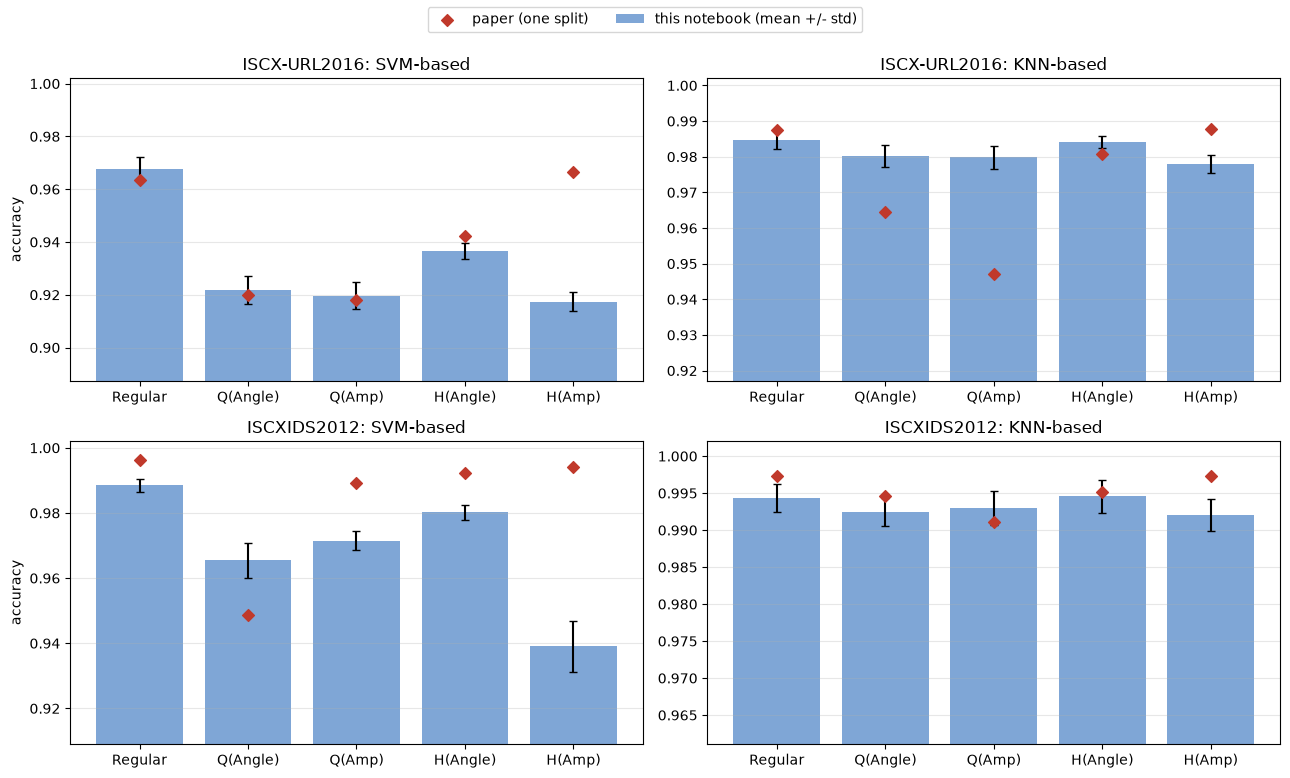

In [11]:
# Accuracy per variant with the paper's value as a marker (Fig. 5 of the paper, with error bars over seeds)
PAPER = {  # (dataset, model, variant): (accuracy, precision, recall, F1), Tables 2 and 3
 ("ISCX-URL2016","SVM","Regular"):(.9634,.9857,.9424,.9635), ("ISCX-URL2016","SVM","Quantum(Angle)"):(.9201,.9207,.9208,.9201),
 ("ISCX-URL2016","SVM","Quantum(Amplitude)"):(.9179,.9178,.9180,.9179), ("ISCX-URL2016","SVM","Hybrid(Angle)"):(.9423,.9674,.9186,.9424),
 ("ISCX-URL2016","SVM","Hybrid(Amplitude)"):(.9667,.9880,.9467,.9669),
 ("ISCX-URL2016","KNN","Regular"):(.9874,.9878,.9878,.9878), ("ISCX-URL2016","KNN","Quantum(Angle)"):(.9645,.9600,.9673,.9637),
 ("ISCX-URL2016","KNN","Quantum(Amplitude)"):(.9471,.9399,.9521,.9460), ("ISCX-URL2016","KNN","Hybrid(Angle)"):(.9808,.9848,.9777,.9812),
 ("ISCX-URL2016","KNN","Hybrid(Amplitude)"):(.9878,.9878,.9885,.9881),
 ("ISCXIDS2012","SVM","Regular"):(.9964,.9973,.9955,.9964), ("ISCXIDS2012","SVM","Quantum(Angle)"):(.9488,.9489,.9488,.9488),
 ("ISCXIDS2012","SVM","Quantum(Amplitude)"):(.9893,.9893,.9893,.9893), ("ISCXIDS2012","SVM","Hybrid(Angle)"):(.9924,.9937,.9910,.9924),
 ("ISCXIDS2012","SVM","Hybrid(Amplitude)"):(.9942,.9964,.9919,.9942),
 ("ISCXIDS2012","KNN","Regular"):(.9973,.9982,.9964,.9973), ("ISCXIDS2012","KNN","Quantum(Angle)"):(.9946,.9938,.9956,.9947),
 ("ISCXIDS2012","KNN","Quantum(Amplitude)"):(.9911,.9947,.9876,.9911), ("ISCXIDS2012","KNN","Hybrid(Angle)"):(.9951,.9955,.9946,.9951),
 ("ISCXIDS2012","KNN","Hybrid(Amplitude)"):(.9973,.9982,.9964,.9973)}

fig, axes = plt.subplots(2, 2, figsize=(13, 7.8))
for r_i, ds in enumerate(("ISCX-URL2016", "ISCXIDS2012")):
    for c_i, model in enumerate(("SVM", "KNN")):
        ax = axes[r_i, c_i]
        sub = RES[(RES.dataset == ds) & (RES.tag == "E1") & (RES.model == model)].groupby("variant").accuracy.agg(["mean", "std"]).reindex(VARIANTS).fillna(0)
        ax.bar(range(5), sub["mean"], yerr=sub["std"], color="#7fa6d6", label="this notebook (mean +/- std)", capsize=3)
        ax.scatter(range(5), [PAPER[(ds, model, v)][0] for v in VARIANTS], color="#c0392b", marker="D", zorder=3, label="paper (one split)")
        lo = min(sub["mean"].min(), min(PAPER[(ds, model, v)][0] for v in VARIANTS))
        ax.set_ylim(max(0.8, lo - 0.03), 1.002); ax.set_xticks(range(5)); ax.set_xticklabels(["Regular", "Q(Angle)", "Q(Amp)", "H(Angle)", "H(Amp)"])
        ax.set_title(f"{ds}: {model}-based"); ax.grid(axis="y", alpha=.3)
        if c_i == 0: ax.set_ylabel("accuracy")
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

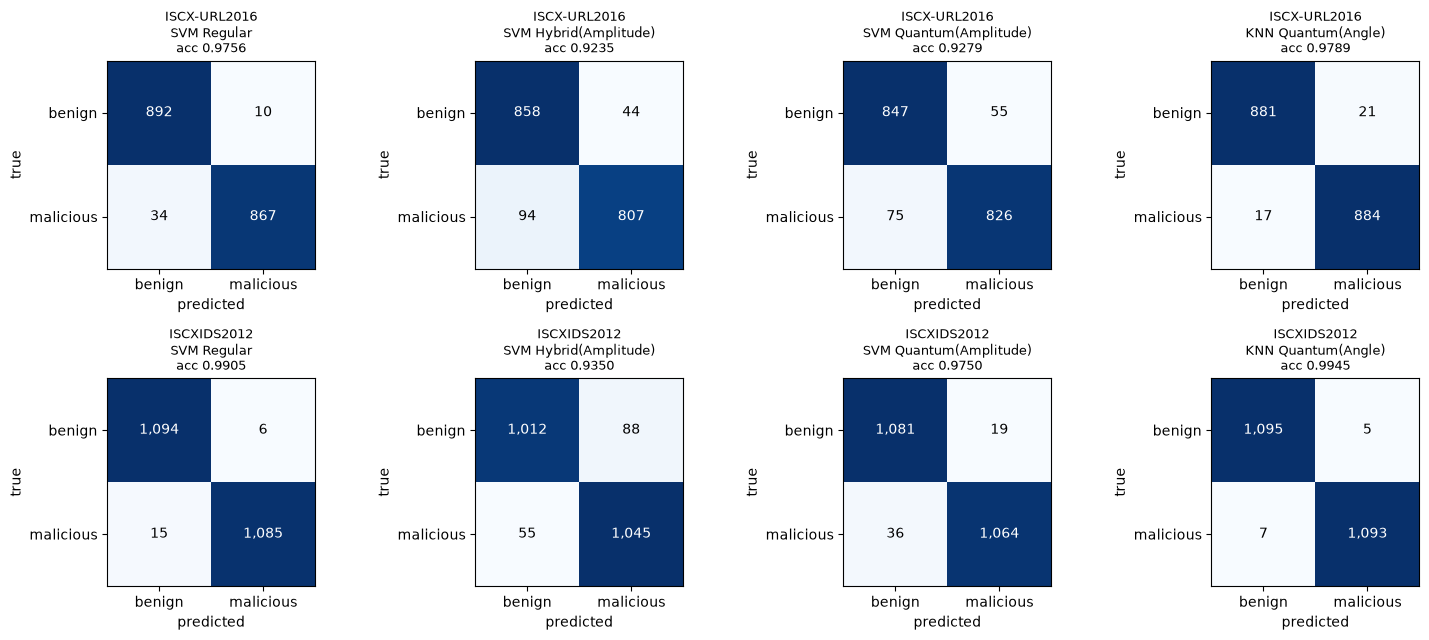

In [12]:
# Confusion matrices (malicious = positive class) of the first seed for four representative models
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
picks = [("SVM", "Regular"), ("SVM", "Hybrid(Amplitude)"), ("SVM", "Quantum(Amplitude)"), ("KNN", "Quantum(Angle)")]
for r_i, ds in enumerate(("ISCX-URL2016", "ISCXIDS2012")):
    for c_i, (model, variant) in enumerate(picks):
        row = RES[(RES.dataset == ds) & (RES.tag == "E1") & (RES.seed == SEEDS[0]) & (RES.model == model) & (RES.variant == variant)].iloc[0]
        cm = np.array([[row.tn, row.fp], [row.fn, row.tp]])
        ax = axes[r_i, c_i]; ax.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f"{v:,d}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["benign", "malicious"]); ax.set_yticklabels(["benign", "malicious"])
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{ds}\n{model} {variant}\nacc {row.accuracy:.4f}", fontsize=9)
plt.tight_layout(); plt.show()

## 6. The paper's Appendix C: pure quantum models on paper-size samples, and the hyper-parameter rows

### 6a. QSVM and QKNN on the paper-size subsets

Appendix C, Table 4 (a, b) reports the pure quantum models on test sets of only **300** (URL) and **240** (IDS) samples (the accuracies are multiples of 1/300 and 1/240), i.e. on
subsets of 1,500 and 1,200 samples because the paper's circuits are slow. Here the same sizes are used (the exact kernel makes it instant), with QKNN at k = 5 and k = 15 as in the paper. The paper
lists `gamma` and `shrinking` options for QSVM; they have no effect on a pre-computed kernel (gamma is ignored, shrinking only changes the solver's speed), so a QSVM row here is compared with the mean of the
two paper rows of the same encoding.

In [13]:
T0 = time.time()
for ds, X, y, nq in (("ISCX-URL2016", URL_X, URL_y, N_Q_URL), ("ISCXIDS2012", IDS_X, IDS_y, N_Q_IDS)):
    for seed in SEEDS:
        run_suite(ds, X, y, nq // 2, seed, "E2", qks=(5, 15), classical=False)
RES = pd.DataFrame(ROWS)
E2 = RES[RES.tag == "E2"].copy()
E2["row"] = E2.model.map({"SVM": "QSVM", "KNN": "QKNN"}) + E2.k.map(lambda k: "" if pd.isna(k) else f" k={int(k)}")
g = E2.groupby(["dataset", "row", "variant"]).accuracy.agg(["mean", "std"]).round(4)
print(f"Section 6a: {time.time()-T0:.0f}s; test sets of {int(E2.n_test.iloc[0])} (URL) / {int(E2[E2.dataset=='ISCXIDS2012'].n_test.iloc[0])} (IDS) samples")
display(g)

Section 6a: 7s; test sets of 300 (URL) / 240 (IDS) samples


mean     std
dataset      row       variant                           
ISCX-URL2016 QKNN k=15 Quantum(Amplitude)  0.9253  0.0239
                       Quantum(Angle)      0.9180  0.0276
             QKNN k=5  Quantum(Amplitude)  0.9547  0.0177
                       Quantum(Angle)      0.9533  0.0139
             QSVM      Quantum(Amplitude)  0.9100  0.0181
                       Quantum(Angle)      0.9053  0.0185
ISCXIDS2012  QKNN k=15 Quantum(Amplitude)  0.9567  0.0086
                       Quantum(Angle)      0.9567  0.0086
             QKNN k=5  Quantum(Amplitude)  0.9800  0.0035
                       Quantum(Angle)      0.9783  0.0035
             QSVM      Quantum(Amplitude)  0.9708  0.0088
                       Quantum(Angle)      0.9600  0.0120

### 6b. Poly-kernel SVM and KNN with k = 5 on the classical and hybrid inputs (Table 4 c, d)

The remaining Appendix-C rows are classical models on the three inputs: `SVC(kernel="poly", degree=3, gamma="auto")` and `KNeighborsClassifier(5)` with the default Minkowski (p = 2, i.e. Euclidean) metric and
uniform weights. They reuse the inputs cached by Section 5.

In [14]:
T0 = time.time()
for (ds, seed, tag), c in list(CACHE.items()):
    if tag != "E1" or seed not in E3_SEEDS:
        continue
    for variant, (Ftr, Fte, _) in c["feats"].items():
        vname = {"Regular": "Regular", "Hybrid(Angle)": "Hybrid(Angle)", "Hybrid(Amplitude)": "Hybrid(Amplitude)"}[variant]
        p, t = fit_predict(KNeighborsClassifier(5, weights="uniform"), Ftr, c["ytr"], Fte); add(ds, "E3", seed, "KNN5", vname, metrics(c["yte"], p), t)
        if variant != "Hybrid(Amplitude)":
            p, t = fit_predict(SVC(kernel="poly", degree=3, gamma="auto"), Ftr, c["ytr"], Fte); add(ds, "E3", seed, "SVM-poly", vname, metrics(c["yte"], p), t)
RES = pd.DataFrame(ROWS)

PAPER_T4 = {  # Table 4 (c, d): accuracy
 ("ISCX-URL2016","SVM-poly","Hybrid(Angle)"):.9005, ("ISCX-URL2016","SVM-poly","Regular"):.8680,
 ("ISCX-URL2016","KNN5","Hybrid(Amplitude)"):.9837, ("ISCX-URL2016","KNN5","Hybrid(Angle)"):.9763, ("ISCX-URL2016","KNN5","Regular"):.9815,
 ("ISCXIDS2012","SVM-poly","Hybrid(Angle)"):.8851, ("ISCXIDS2012","SVM-poly","Regular"):.9328,
 ("ISCXIDS2012","KNN5","Hybrid(Amplitude)"):.9969, ("ISCXIDS2012","KNN5","Hybrid(Angle)"):.9942, ("ISCXIDS2012","KNN5","Regular"):.9964}
e3 = RES[RES.tag == "E3"].groupby(["dataset", "model", "variant"]).accuracy.agg(["mean", "std"]).round(4)
e3["paper"] = [PAPER_T4.get(i, np.nan) for i in e3.index]
e3["gap"] = (e3["mean"] - e3["paper"]).round(4)
print(f"Section 6b: {time.time()-T0:.0f}s over seeds {E3_SEEDS}")
display(e3)

Section 6b: 13s over seeds [42, 43, 44]


mean     std   paper     gap
dataset      model    variant                                          
ISCX-URL2016 KNN5     Hybrid(Amplitude)  0.9717  0.0010  0.9837 -0.0120
                      Hybrid(Angle)      0.9773  0.0020  0.9763  0.0010
                      Regular            0.9824  0.0016  0.9815  0.0009
             SVM-poly Hybrid(Angle)      0.8954  0.0117  0.9005 -0.0051
                      Regular            0.9621  0.0050  0.8680  0.0941
ISCXIDS2012  KNN5     Hybrid(Amplitude)  0.9897  0.0028  0.9969 -0.0072
                      Hybrid(Angle)      0.9926  0.0018  0.9942 -0.0016
                      Regular            0.9933  0.0011  0.9964 -0.0031
             SVM-poly Hybrid(Angle)      0.9320  0.0018  0.8851  0.0469
                      Regular            0.9870  0.0014  0.9328  0.0542

## 7. Ablation: what if the IP addresses and the source port are removed?

The paper label-encodes *all* categorical columns of ISCXIDS2012, which includes the source and destination IP addresses, and keeps the (ephemeral) source port. In this testbed a handful of hosts generate
the attacks, so those columns identify the attack almost by themselves; that is a property of the lab, not of encrypted traffic. The experiment below drops `source`, `destination` and `sourcePort`
and reruns all models for the first seed.

In [15]:
T0 = time.time()
IDS_X2, IDS_y2 = prepare_ids(ids_raw, drop_cols=("source", "destination", "sourcePort"))
print(f"IDS without IPs/source port: {len(IDS_X2):,d} rows after de-duplication (was {len(IDS_X):,d}), malicious {int(IDS_y2.sum()):,d}, {IDS_X2.shape[1]} features")
run_suite("ISCXIDS2012 (no IP)", IDS_X2, IDS_y2, IDS_PER_CLASS, SEEDS[0], "E4")
RES = pd.DataFrame(ROWS)
a = RES[(RES.tag == "E4")].set_index(["model", "variant"]).accuracy.rename("no IP / sport")
b = RES[(RES.tag == "E1") & (RES.dataset == "ISCXIDS2012") & (RES.seed == SEEDS[0])].set_index(["model", "variant"]).accuracy.rename("with IP (paper setting)")
abl = pd.concat([b, a], axis=1).dropna(); abl["drop"] = (abl.iloc[:, 0] - abl.iloc[:, 1]).round(4)
print(f"Section 7: {time.time()-T0:.0f}s")
display(abl.round(4))

IDS without IPs/source port: 146,194 rows after de-duplication (was 414,149), malicious 4,336, 10 features


Section 7: 34s


,,with IP (paper setting),no IP / sport,drop
model,variant,,,
SVM,Regular,0.9905,0.9723,0.0181
KNN,Regular,0.9968,0.9793,0.0176
SVM,Hybrid(Angle),0.9832,0.9671,0.0160
KNN,Hybrid(Angle),0.9973,0.9798,0.0174
SVM,Hybrid(Amplitude),0.9350,0.9671,-0.0321
KNN,Hybrid(Amplitude),0.9950,0.9810,0.0140
RF,Regular,0.9982,0.9873,0.0109
SVM,Quantum(Angle),0.9668,0.9441,0.0227
KNN,Quantum(Angle),0.9945,0.9798,0.0147


## 8. The cost of "one circuit per kernel entry"

The paper's pure quantum models took one to two orders of magnitude longer than the classical and hybrid ones because every Gram-matrix entry and every test-train fidelity is a separate circuit
execution. The exact-state shortcut used above hides that cost. The cell below times real PennyLane kernel circuits (`lightning.qubit`, one core) and extrapolates to the number of circuits that
QSVM (lower triangle of the Gram matrix plus the test-train block) and QKNN (test-train block) would need on the Section 5 data, compared with the measured classical SVM time. Note that a single-circuit call costs 10-50 ms here mostly because of PennyLane's Python/QNode overhead, not because 4-15 qubits are hard to simulate;
the paper spreads the circuits over all CPU cores with joblib, which divides the estimate by the number of cores but leaves the quadratic growth in the number of circuits.

In [16]:
def time_circuits(kind, d, reps=40):
    a_, b_ = rng.random((reps, d)), rng.random((reps, d))
    t = time.time()
    for i in range(reps):
        kernel_circuit(a_[i], b_[i], kind)
    return (time.time() - t) / reps

cost = []
for ds, d in (("ISCX-URL2016", URL_X.shape[1]), ("ISCXIDS2012", IDS_X.shape[1])):
    r = RES[(RES.dataset == ds) & (RES.tag == "E1")]
    ntr, nte = int(r.n_train.iloc[0]), int(r.n_test.iloc[0])
    t_cls = r[(r.model == "SVM") & (r.variant == "Regular")].seconds.mean()
    for kind, name in (("angle", "Angle"), ("amp", "Amplitude")):
        per = time_circuits(kind, d)
        n_svm = ntr * (ntr + 1) // 2 + nte * ntr; n_knn = nte * ntr
        cost.append(dict(dataset=ds, encoding=name, qubits=d if kind == "angle" else n_amp_qubits(d), s_per_circuit=round(per, 4),
                         QSVM_circuits=n_svm, QSVM_est_hours=round(n_svm * per / 3600, 1), QKNN_est_hours=round(n_knn * per / 3600, 1),
                         classical_SVM_s=round(t_cls, 2), slowdown_QSVM=round(n_svm * per / max(t_cls, 1e-3))))
COST = pd.DataFrame(cost)
display(COST)

,dataset,encoding,qubits,s_per_circuit,QSVM_circuits,QSVM_est_hours,QKNN_est_hours,classical_SVM_s,slowdown_QSVM
0,ISCX-URL2016,Angle,15,0.0068,38986272,73.3,24.4,2.73,96657
1,ISCX-URL2016,Amplitude,4,0.0103,38986272,111.3,37.1,2.73,146725
2,ISCXIDS2012,Angle,13,0.0053,58084400,85.6,28.5,1.10,281246
3,ISCXIDS2012,Amplitude,4,0.0100,58084400,161.3,53.8,1.10,530055


## 9. Side by side with the paper

Rule for the verdicts (set before looking at the numbers): a number is **reproduced** when both our mean accuracy and our mean F1 are within 0.02 of the paper's; otherwise **not reached** (ours lower) or **exceeded**
(ours higher), with the gap shown. The paper's values are single-split point estimates without error bars, so "reproduced" means "inside a band around the paper's number", not "statistically equal".

In [17]:
def verdict(mine_acc, paper_acc, mine_f1, paper_f1, tol=0.02):
    if abs(mine_acc - paper_acc) <= tol and abs(mine_f1 - paper_f1) <= tol:
        return "reproduced"
    return "exceeded" if mine_acc > paper_acc else "not reached"

comp = []
E1 = RES[RES.tag == "E1"]
for (ds, model, variant), (pa, pp, pr, pf) in PAPER.items():
    r = E1[(E1.dataset == ds) & (E1.model == model) & (E1.variant == variant)]
    ma, sa, mf = r.accuracy.mean(), r.accuracy.std(), r.f1.mean()
    comp.append(dict(dataset=ds, model=model, variant=variant, paper_acc=pa, notebook_acc=f"{ma:.4f} +/- {0 if np.isnan(sa) else sa:.4f}",
                     gap_acc=round(ma - pa, 4), paper_F1=pf, notebook_F1=round(mf, 4), verdict=verdict(ma, pa, mf, pf)))
COMP = pd.DataFrame(comp)
display(COMP)
print(COMP.groupby("dataset").verdict.value_counts().unstack(fill_value=0))

,dataset,model,variant,paper_acc,notebook_acc,gap_acc,paper_F1,notebook_F1,verdict
0,ISCX-URL2016,SVM,Regular,0.9634,0.9676 +/- 0.0046,0.0042,0.9635,0.9670,reproduced
1,ISCX-URL2016,SVM,Quantum(Angle),0.9201,0.9218 +/- 0.0054,0.0017,0.9201,0.9204,reproduced
2,ISCX-URL2016,SVM,Quantum(Amplitude),0.9179,0.9197 +/- 0.0052,0.0018,0.9179,0.9187,reproduced
3,ISCX-URL2016,SVM,Hybrid(Angle),0.9423,0.9367 +/- 0.0031,-0.0056,0.9424,0.9350,reproduced
4,ISCX-URL2016,SVM,Hybrid(Amplitude),0.9667,0.9174 +/- 0.0037,-0.0493,0.9669,0.9152,not reached
5,ISCX-URL2016,KNN,Regular,0.9874,0.9848 +/- 0.0026,-0.0026,0.9878,0.9848,reproduced
6,ISCX-URL2016,KNN,Quantum(Angle),0.9645,0.9803 +/- 0.0031,0.0158,0.9637,0.9803,reproduced
7,ISCX-URL2016,KNN,Quantum(Amplitude),0.9471,0.9798 +/- 0.0033,0.0327,0.9460,0.9799,exceeded
8,ISCX-URL2016,KNN,Hybrid(Angle),0.9808,0.9841 +/- 0.0016,0.0033,0.9812,0.9841,reproduced
9,ISCX-URL2016,KNN,Hybrid(Amplitude),0.9878,0.9780 +/- 0.0025,-0.0098,0.9881,0.9779,reproduced


verdict       exceeded  not reached  reproduced
dataset                                        
ISCX-URL2016         1            1           8
ISCXIDS2012          0            1           9


In [18]:
# Appendix C rows (Table 4): same rule, accuracy only
rows = []
P4A = {("ISCX-URL2016","QSVM","Quantum(Angle)"):np.mean([.8933,.8967]), ("ISCX-URL2016","QSVM","Quantum(Amplitude)"):np.mean([.8967,.8867]),
       ("ISCX-URL2016","QKNN k=5","Quantum(Angle)"):.9233, ("ISCX-URL2016","QKNN k=15","Quantum(Angle)"):.8967,
       ("ISCX-URL2016","QKNN k=5","Quantum(Amplitude)"):.8233, ("ISCX-URL2016","QKNN k=15","Quantum(Amplitude)"):.7700,
       ("ISCXIDS2012","QSVM","Quantum(Angle)"):np.mean([.9667,.9458]), ("ISCXIDS2012","QSVM","Quantum(Amplitude)"):np.mean([.9750,.9458]),
       ("ISCXIDS2012","QKNN k=5","Quantum(Angle)"):.9708, ("ISCXIDS2012","QKNN k=15","Quantum(Angle)"):.9542,
       ("ISCXIDS2012","QKNN k=5","Quantum(Amplitude)"):.9667, ("ISCXIDS2012","QKNN k=15","Quantum(Amplitude)"):.8750}
for (ds, row, variant), pa in P4A.items():
    r = E2[(E2.dataset == ds) & (E2.row == row) & (E2.variant == variant)]
    ma = r.accuracy.mean()
    rows.append(dict(table="4a/4b", dataset=ds, row=f"{row} {variant}", paper_acc=round(pa, 4), notebook_acc=round(ma, 4), gap=round(ma - pa, 4),
                     verdict="reproduced" if abs(ma - pa) <= 0.02 else ("exceeded" if ma > pa else "not reached")))
for (ds, model, variant), pa in PAPER_T4.items():
    r = RES[(RES.tag == "E3") & (RES.dataset == ds) & (RES.model == model) & (RES.variant == variant)]
    ma = r.accuracy.mean()
    rows.append(dict(table="4c/4d", dataset=ds, row=f"{model} {variant}", paper_acc=pa, notebook_acc=round(ma, 4), gap=round(ma - pa, 4),
                     verdict="reproduced" if abs(ma - pa) <= 0.02 else ("exceeded" if ma > pa else "not reached")))
COMP4 = pd.DataFrame(rows)
display(COMP4)
print(COMP4.verdict.value_counts().to_dict())

,table,dataset,row,paper_acc,notebook_acc,gap,verdict
0,4a/4b,ISCX-URL2016,QSVM Quantum(Angle),0.8950,0.9053,0.0103,reproduced
1,4a/4b,ISCX-URL2016,QSVM Quantum(Amplitude),0.8917,0.9100,0.0183,reproduced
2,4a/4b,ISCX-URL2016,QKNN k=5 Quantum(Angle),0.9233,0.9533,0.0300,exceeded
3,4a/4b,ISCX-URL2016,QKNN k=15 Quantum(Angle),0.8967,0.9180,0.0213,exceeded
4,4a/4b,ISCX-URL2016,QKNN k=5 Quantum(Amplitude),0.8233,0.9547,0.1314,exceeded
5,4a/4b,ISCX-URL2016,QKNN k=15 Quantum(Amplitude),0.7700,0.9253,0.1553,exceeded
6,4a/4b,ISCXIDS2012,QSVM Quantum(Angle),0.9562,0.9600,0.0037,reproduced
7,4a/4b,ISCXIDS2012,QSVM Quantum(Amplitude),0.9604,0.9708,0.0104,reproduced
8,4a/4b,ISCXIDS2012,QKNN k=5 Quantum(Angle),0.9708,0.9783,0.0075,reproduced
9,4a/4b,ISCXIDS2012,QKNN k=15 Quantum(Angle),0.9542,0.9567,0.0025,reproduced


{'reproduced': 14, 'exceeded': 8}


In [19]:
# Qualitative claims of Section 5.2 / 6, checked on the mean accuracies of Section 5
M = E1.groupby(["dataset", "model", "variant"]).accuracy.mean()
DS = ("ISCX-URL2016", "ISCXIDS2012")
SH = {"ISCX-URL2016": "URL", "ISCXIDS2012": "IDS"}
claims = []

# C1: hybrid amplitude is on par with or better than the regular classifier (on par = not more than 0.5 point lower)
d = {(ds, m): M[(ds, m, "Hybrid(Amplitude)")] - M[(ds, m, "Regular")] for ds in DS for m in ("SVM", "KNN")}
claims.append(("C1 Hybrid(Amp) on par with or better than Regular (>= -0.5 pt)", "reproduced" if all(v >= -0.005 for v in d.values()) else "not reached",
               "; ".join(f"{SH[ds]} {m}: {v*100:+.2f} pt" for (ds, m), v in d.items()) + "  (paper: +0.33, +0.04, -0.22, 0.00 pt)"))
# C2: hybrid beats the pure quantum model with the same encoding and classifier family
pairs_ = [(ds, m, e) for ds in DS for m in ("SVM", "KNN") for e in ("Angle", "Amplitude")]
n_ok = sum(M[(ds, m, f"Hybrid({e})")] >= M[(ds, m, f"Quantum({e})")] - 1e-4 for ds, m, e in pairs_)
claims.append(("C2 Hybrid >= pure quantum, same encoding and family", "reproduced" if n_ok == len(pairs_) else (f"partly reproduced ({n_ok}/{len(pairs_)})"), f"{n_ok} of {len(pairs_)} comparisons (paper: 8 of 8)"))
# C3: KNN-based models beat SVM-based models on both datasets
n_knn = sum(M[(ds, "KNN", v)] >= M[(ds, "SVM", v)] for ds in DS for v in VARIANTS)
claims.append(("C3 KNN-based >= SVM-based, same variant", "reproduced" if n_knn == 10 else (f"partly reproduced ({n_knn}/10)"), f"{n_knn} of 10 comparisons (paper: 10 of 10)"))
# C4: on URL the pure quantum models lag behind the regular classifiers
n_lag = sum(M[("ISCX-URL2016", m, f"Quantum({e})")] < M[("ISCX-URL2016", m, "Regular")] for m in ("SVM", "KNN") for e in ("Angle", "Amplitude"))
claims.append(("C4 URL: pure quantum models lag behind Regular", "reproduced" if n_lag == 4 else (f"partly reproduced ({n_lag}/4)"), f"{n_lag} of 4 (paper: 4 of 4)"))
# C5: amplitude is at least as good as angle encoding for the hybrid SVM
d5 = {ds: M[(ds, "SVM", "Hybrid(Amplitude)")] - M[(ds, "SVM", "Hybrid(Angle)")] for ds in DS}
claims.append(("C5 Hybrid SVM: Amplitude >= Angle", "reproduced" if all(v >= 0 for v in d5.values()) else "not reached", "; ".join(f"{SH[k]}: {v*100:+.2f} pt" for k, v in d5.items()) + "  (paper: +2.44, +0.18 pt)"))
# C6: simulating the pure quantum models circuit by circuit is 1-2 orders of magnitude slower than classical
claims.append(("C6 Circuit-level QSVM is >= 10x slower than classical SVM", "reproduced" if (COST.slowdown_QSVM >= 10).all() else "not reached",
               "extrapolated slowdown " + ", ".join(f"{SH[r.dataset]} {r.encoding}: {int(r.slowdown_QSVM):,d}x" for r in COST.itertuples()) + " (paper: 10-100x with joblib on many cores)"))
# C7: not checkable
claims.append(("C7 Statements about encrypted traffic / real hardware / deep-learning baselines", "cannot be checked",
               "the datasets are URL-lexical features and unencrypted-lab flow records, the paper used simulators only, and no deep-learning baseline is reported"))
CLAIMS = pd.DataFrame(claims, columns=["claim", "verdict", "evidence"])
pd.set_option("display.max_colwidth", 200)
display(CLAIMS)

,claim,verdict,evidence
0,C1 Hybrid(Amp) on par with or better than Regular (>= -0.5 pt),not reached,"URL SVM: -5.02 pt; URL KNN: -0.68 pt; IDS SVM: -4.94 pt; IDS KNN: -0.24 pt (paper: +0.33, +0.04, -0.22, 0.00 pt)"
1,"C2 Hybrid >= pure quantum, same encoding and family",partly reproduced (4/8),4 of 8 comparisons (paper: 8 of 8)
2,"C3 KNN-based >= SVM-based, same variant",reproduced,10 of 10 comparisons (paper: 10 of 10)
3,C4 URL: pure quantum models lag behind Regular,reproduced,4 of 4 (paper: 4 of 4)
4,C5 Hybrid SVM: Amplitude >= Angle,not reached,"URL: -1.93 pt; IDS: -4.11 pt (paper: +2.44, +0.18 pt)"
5,C6 Circuit-level QSVM is >= 10x slower than classical SVM,reproduced,"extrapolated slowdown URL Angle: 96,657x, URL Amplitude: 146,725x, IDS Angle: 281,246x, IDS Amplitude: 530,055x (paper: 10-100x with joblib on many cores)"
6,C7 Statements about encrypted traffic / real hardware / deep-learning baselines,cannot be checked,"the datasets are URL-lexical features and unencrypted-lab flow records, the paper used simulators only, and no deep-learning baseline is reported"


In [20]:
print("Run time of this notebook:", round((time.time() - NOTEBOOK_T0) / 60, 1), "min  | FAST_MODE =", FAST_MODE, "| seeds =", SEEDS)
print("\nVerdicts, Tables 2-3 (accuracy and F1 within 0.02):", COMP.verdict.value_counts().to_dict())
print("Verdicts, Table 4 rows (accuracy within 0.02):     ", COMP4.verdict.value_counts().to_dict())
print("Verdicts, qualitative claims:                      ", CLAIMS.verdict.value_counts().to_dict())

Run time of this notebook: 28.5 min  | FAST_MODE = False | seeds = [42, 43, 44, 45, 46]

Verdicts, Tables 2-3 (accuracy and F1 within 0.02): {'reproduced': 17, 'not reached': 2, 'exceeded': 1}
Verdicts, Table 4 rows (accuracy within 0.02):      {'reproduced': 14, 'exceeded': 8}
Verdicts, qualitative claims:                       {'reproduced': 3, 'not reached': 2, 'partly reproduced (4/8)': 1, 'cannot be checked': 1}


## Reading the paper critically

1. **"Encrypted traffic" is not what the data contain.** ISCX-URL2016 is a table of lexical features of URLs (length, digit counts, entropy of the domain, ...); ISCXIDS2012 is a flow summary of a
   2010 lab testbed that is mostly unencrypted HTTP/FTP/SSH. Neither dataset is a benchmark of *encrypted* traffic classification (ISCX VPN-nonVPN or USTC-TFC would be). The title and the industrial-control
   discussion are broader than the experiments, and the first claim cannot be checked here.
2. **The URL task is two of five classes.** Only benign vs *defacement* is used, the easiest of the URL attack types to separate by lexical statistics, and the classical KNN already reaches about 0.98-0.99.
3. **IP addresses and ports as features.** Label-encoded source/destination addresses identify the few attacker hosts of the testbed. Section 7 shows how much accuracy depends on them; a model that learns "which host sent it" has
   learned the lab, not the attack.
4. **De-duplication before the split is not enough.** Flows from one session share addresses, ports and sizes; random splits put near-identical flows on both sides, which inflates every model (classical and quantum) on IDS.
5. **A single split, no error bars.** The differences the paper highlights are small ($\le$ 0.5 points). Our seed-to-seed standard deviations (Section 5) are of the same order, so "hybrid is slightly better than classical" is
   not established in either direction.
6. **What the "quantum" kernels compute.** Angle encoding gives a *product state*: the kernel is $\prod_i\cos^2((a_i-b_i)/2)$, a classically trivial function (verified above against the circuit) and, for small angles,
   close to a Gaussian kernel. Amplitude encoding gives $K(a,b)=\left(\frac{a\cdot b}{\|a\|\|b\|}\right)^2$, the squared cosine similarity, i.e. a homogeneous degree-2 polynomial kernel on normalised vectors (the Gram matrix of the
   code above equals it exactly). Neither uses entanglement, neither is hard to simulate, and the CNOT/RY layers in the QKNN circuit cancel out of every fidelity (Section 3). Nothing here could be a quantum advantage; the paper itself is cautious
   about this, but "the quantum kernel trick maps data into an exponentially large space" overstates what these two encodings do.
7. **The hybrid model is a classical feature map.** With angle encoding the read-out is $\cos(x_i)$ per feature, a monotone element-wise transform; with amplitude encoding it is four numbers, signed sums of squared normalised features. Calling the result "quantum-enhanced"
   is a naming choice; the effect on SVM/KNN is that of a fixed non-linear rescaling (and, for amplitude, a compression to 4 features that discards the vector norm).
8. **Under-specified details.** Scalers for the quantum models, the QSVM `C`, the QKNN `k`, the train/test ratio and the IDS columns kept are not given; these choices move our numbers by more than the claimed differences.
9. **Run time.** The reported slowness of the quantum models is a property of simulating one circuit per kernel entry (Section 8). With state vectors the same kernels are as cheap as a classical SVM; on real hardware the number of circuits would still be quadratic in the training set.

## Exercises

1. **Seeds.** Set `SEEDS` to ten values and compute a paired difference (hybrid amplitude minus regular) for the KNN on ISCX-URL2016. How often is the sign positive, as the paper reports?
2. **Angle scale.** The angles are features in $[0,1]$ rad. Multiply `Qtr`/`Qte` by 2 or by $\pi$ before the angle encoding and rerun Section 5 for the QSVM only. Pick the scale on a validation split of the training data (never on the test set). Does the QSVM ranking against the RBF SVM change?
3. **Prove the shortcuts.** Show numerically that the amplitude Gram matrix equals the squared cosine similarity matrix, and that the angle Gram matrix is close to an RBF kernel of the same features for small angles. What does this say about the claim of an "exponentially large feature space"?
4. **More qubits for the hybrid read-out.** Replace the 4-qubit amplitude read-out by 8 qubits (pad the vector with zeros to 256 entries) and add two-qubit correlators $\langle Z_iZ_j\rangle$ as features. Does the hybrid SVM close the gap to the classical SVM?
5. **A genuinely encrypted dataset.** Swap the loaders for flow features of an encrypted-traffic dataset (for example ISCX VPN-nonVPN time-based features, which the `ISCXVPN2016` CSVs provide): keep Sections 3-5 unchanged and report whether the ordering Regular > Hybrid > Quantum survives.